# HOMEWORK 16 - Course Project

Done by: **Bohdan Pinchuk**

Link: https://github.com/BogdanPinchuk/ComputerVision-PBY_HW16_Course_Project

- **Dataset:** BSD432 / CBSD432 (train), BSD68 / CBSD68 (test)
- **Тип задачі:** Тема 2 — Intelligent Denoising based on Autoencoders
- **Вимога курсового проєкту:** обов'язкове порівняння з фільтрацією Гауса
- **Узгодження з лектором (Ján Koloda):** затверджено напрям Denoising; схвалено датасети родини BSD та генерацію шуму «на льоту» як аугментацію
- **Мета:** дослідити та порівняти ефективність класичного бейслайну (фільтр Гауса, медіанний фільтр), згорткового автоенкодера (CNN) та спектрального підходу (Fourier KAN)

---

### Контекст задачі (Motivation)

Потрібно побудувати та дослідити пайплайн для інтелектуального усунення шуму із цифрових зображень (як чорно-білих, так і кольорових).

Відповідно до вимог теми 2 курсового проєкту, ключовими завданнями є:
- порівняння якості денойзингу відносно обов'язкового бейслайну Гауса (*Gaussian filtering*);
- дослідження стійкості алгоритмів до різних типів шуму (гаусівський, періодичний тощо);
- збереження дрібних деталей, контурів та текстур без ефекту «розмиття» (blurring);
- оцінка ефективності, швидкості обробки та сильних/слабких сторін кожного методу.

---
# Поетапний план реалізації проєкту (Roadmap)

## Етап 1 — Data Preparation & Loading (Підготовка та завантаження даних)

Що потрібно зробити:
- підготувати та структурувати каталоги для збереження зображень (`resources/data/`);
- завантажити/зчитати тренувальний набір (BSD432 / CBSD432) та тестовий бенчмарк (BSD68 / CBSD68);
- забезпечити універсальну підтримку як чорно-білих (монохромних), так і кольорових (RGB) зображень.

---

## Етап 2 — EDA & Noise Injection (Аналіз структури та контамінація шумом)

Що потрібно зробити:
- перевірити розмірності, орієнтацію та діапазон значень пікселів у датасеті;
- реалізувати генерацію різних типів шуму «на льоту» як аугментацію (гаусівський шум, періодичні смуги тощо);
- візуалізувати зашумлені зразки та їхній частотний спектр (2D FFT) для аналізу природи шуму.

---

## Етап 3 — Baseline 1: Spatial Filtering (Класична просторова фільтрація)

Що потрібно зробити:
- реалізувати методи просторової фільтрації без навчання:
  - медіанний фільтр для оцінки придушення локальних аномалій;
  - фільтр Гауса (обов'язковий бейслайн за вимогою курсового проєкту);
  - білатеральний фільтр для перевірки збереження меж;
- розрахувати базові метрики відновлення (MSE, MAE, PSNR, SSIM тощо).

---

## Етап 4 — Baseline 2: Convolutional Autoencoder (Базова згорткова нейромережа)

Що потрібно зробити:
- побудувати згортковий автоенкодер (Baseline CNN) із гнучкою функцією активації (SiLU / GELU / LeakyReLU / ELU тощо);
- налаштувати навчальний пайплайн на патчах $96 	imes 96$ з оптимізатором;
- проаналізувати криві збіжності функції втрат (Loss) та зафіксувати базову якість.

---

## Етап 5 — Hyperparameter Tuning: Baseline CNN (Підбір гіперпараметрів згорткової мережі)

Що потрібно зробити:
- визначити простір ключових параметрів для оптимізації базової згорткової мережі (активації, швидкість навчання тощо);
- виконати цільовий пошук оптимальної конфігурації через Optuna на підвибірці патчів для досягнення максимальної якості CNN;
- зафіксувати найкращі параметри та зберегти оптимізовану модель бейслайну.

---

## Етап 6 — Novel Model: Fourier KAN (Спектральний автоенкодер)

Що потрібно зробити:
- побудувати архітектуру Fourier KAN із нелінійними вагами на базі гармонійних ядер;
- провести базове навчання моделі за ідентичних умов (той самий датасет і кількість епох для чесного порівняння);
- проаналізувати початкову динаміку навчання та спектральні особливості.

---

## Етап 7 — Hyperparameter Tuning: Fourier KAN (Підбір гіперпараметрів спектральної моделі)

Що потрібно зробити:
- визначити простір ключових параметрів для оптимізації спектральної моделі (гармонійні сітки, параметри оптимізації тощо);
- виконати цільовий пошук оптимальних конфігурацій через Optuna на підвибірці патчів для досягнення максимальної ефективності Fourier KAN;
- зафіксувати найкращі конфігурації та навчити фінальну спектральну модель.

---

## Етап 8 — Benchmarking & Evaluation (Зведена таблиця метрик)

Що потрібно зробити:
- протестувати всі три підходи на контрольному наборі BSD68 / CBSD68;
- розрахувати готові бібліотечні метрики: попіксельні помилки та якість сприйняття (MSE, RMSE, MAE, PSNR, SSIM тощо);
- виміряти швидкість обробки одного кадру (Latency в мс) та кількість параметрів кожної моделі;
- побудувати зведену форматовану таблицю порівняння через `Reporter`.

---

## Етап 9 — Visual & Spectral Analysis (Візуальна та спектральна діагностика)

Що потрібно зробити:
- побудувати радіальний графік спектра енергії (Radial Power Spectrum) для перевірки збереження високих частот і текстур;
- сформувати порівняльну візуальну сітку відновлених зображень;
- побудувати карти залишкових помилок (Residual Error Maps) для наочної демонстрації сильних і слабких сторін кожного підходу.

---

## Етап 10 — Conclusions & Discussion (Висновки та підсумки)

Що потрібно зробити:
- узагальнити отримані результати за основними критеріями оцінювання проєкту;
- сформувати чіткі підсумкові тези (ефективність методів, швидкість роботи, висновки щодо спектрального підходу).

In [2]:
# # Silent installation or update
#
# import sys
# from packaging.requirements import Requirement
# from importlib.metadata import PackageNotFoundError, version
#
# # Clean cache
# !"{sys.executable}" -m pip cache purge -q
#
# # Force updating
# package_update = [
#     "pip",
#     "scikit-learn",
#     "pandas",
# ]
#
# for package_name in package_update:
#     !"{sys.executable}" -m pip install -U "{package_name}" -q
#
# # Install missing packages
# package_array = [
#     "jinja2",
#     "ipywidgets",
#     "nbformat",
#     "numpy",
#     "matplotlib",
#     "opencv-contrib-python",
#     "torch",
#     "torchvision",
#     "scikit-image",
#     "optuna",
# ]
#
#
# def is_package_satisfied(req_str: str) -> bool:
#     try:
#         req = Requirement(req_str)
#         installed_ver = version(req.name)
#         if req.specifier:
#             return installed_ver in req.specifier
#         return True
#     except PackageNotFoundError:
#         return False
#
#
# for package_name in package_array:
#     if not is_package_satisfied(package_name):
#         !"{sys.executable}" -m pip install "{package_name}" -q


In [ ]:
# # Synchronization with remote source
#
# import shutil
# from pathlib import Path
#
# # Input data
# hm_version = 16
#
# # Solution
# git_project_url = f"https://github.com/BogdanPinchuk/ComputerVision-PBY_HW{hm_version}_Course_Project.git"
# main_file_name_ua = f"Bohdan_Pinchuk_CV_HW{hm_version}_UA.ipynb"
# main_file_name = f"Bohdan_Pinchuk_CV_HW{hm_version}.ipynb"
#
# # upload all files
# current_path = !pwd
# current_path = current_path[0]
# parent_path = !dirname "$current_path"
# parent_path = parent_path[0]
# temp_path = f"{parent_path}/temp"
#
# # Clone data
# !rm -rf "$temp_path"
# !git clone "$git_project_url" "$temp_path"
#
# source = Path(temp_path)
# destination = Path(current_path)
# exclude = {main_file_name_ua, main_file_name, ".git", ".idea", ".DS_Store"}
#
# for item in source.iterdir():
#     if item.name in exclude:
#         continue
#
#     target = destination / item.name
#     if item.is_dir():
#         shutil.copytree(item, target, dirs_exist_ok=True)
#     else:
#         shutil.copy2(item, target)
#
# # Clean temp folder
# !rm -rf "$temp_path"
#
# # Note. To upload big files to GitHub, execute the next command in the terminal
# # 1. brew install git-lfs
# # 2. git lfs install
# # 3.1. git lfs track "*.safetensors"
# # 3.2. git lfs track "*.bin"

## ✅ Рішення: Етап 1 — Data Preparation & Loading (Підготовка та завантаження даних)

Що потрібно зробити:
- підготувати та структурувати каталоги для збереження зображень (`resources/data/`);
- завантажити/зчитати тренувальний набір (BSD432 / CBSD432) та тестовий бенчмарк (BSD68 / CBSD68);
- забезпечити універсальну підтримку як чорно-білих (монохромних), так і кольорових (RGB) зображень.

In [36]:
# Downloading data

import os
import cv2
import zipfile
import importlib
import numpy as np
from pathlib import Path

# has to be set before keras is imported
os.environ['KERAS_BACKEND'] = 'torch'
os.environ['KERAS_HOME'] = os.path.abspath('resources/data')
from keras.utils import get_file
from itertools import islice
from PIL import Image
import apps.reporter as rpt

importlib.reload(rpt)

# Input data
n_preview_samples = 4
rng_seed = 42
folder_name = "resources/data"
dataset_zip_url_c = "https://github.com/liutianlin0121/BSD-432-68/archive/refs/heads/master.zip"
archive_name = "cbsd_432_68.zip"
train_c_name = "CBSD432"
test_c_name = "CBSD68"
train_bw_name = "BSD432"
test_bw_name = "BSD68"

# Solution
folder_path = Path(folder_name)
folder_path.mkdir(parents=True, exist_ok=True)

archive_path = folder_path / archive_name
train_c_dir = folder_path / train_c_name
test_c_dir = folder_path / test_c_name
train_bw_dir = folder_path / train_bw_name
test_bw_dir = folder_path / test_bw_name

# download archive
if not archive_path.exists():
    get_file(fname=archive_name,
             origin=dataset_zip_url_c,
             extract=False,
             cache_dir=str(folder_path.parent.resolve()),
             cache_subdir="data")

# check is need to extract
need_extract = not (train_c_dir.exists() and test_c_dir.exists() and
                    len(list(islice(train_c_dir.glob("*.jpg"), 432))) == 432 and
                    len(list(islice(test_c_dir.glob("*.jpg"), 68))) == 68)

# download and extract dataset
if need_extract:
    # check folders
    train_c_dir.mkdir(parents=True, exist_ok=True)
    test_c_dir.mkdir(parents=True, exist_ok=True)
    target_mapping = {
        f"{train_c_name}/": train_c_dir,
        f"{test_c_name}/": test_c_dir,
    }
    # extract
    with zipfile.ZipFile(archive_path, "r") as zf:
        for member in zf.namelist():
            if member.endswith((".jpg", ".png")):
                for prefix, target_dir in target_mapping.items():
                    if prefix in member:
                        filename = os.path.basename(member)
                        if filename:
                            with zf.open(member) as src, open(target_dir / filename, "wb") as dst:
                                dst.write(src.read())
                        break

# check is need to convert
need_convert = not (
        train_bw_dir.exists() and test_bw_dir.exists() and
        len(list(islice(train_bw_dir.glob("*.png"), 432))) == 432 and
        len(list(islice(test_bw_dir.glob("*.png"), 68))) == 68
)

# convert dataset
if need_convert:
    # check folders
    train_bw_dir.mkdir(parents=True, exist_ok=True)
    test_bw_dir.mkdir(parents=True, exist_ok=True)
    pairs = [
        (train_c_dir, train_bw_dir),
        (test_c_dir, test_bw_dir)
    ]
    for src_dir, dst_dir in pairs:
        for img_path in sorted(src_dir.glob("*.jpg")):
            bw_img_path = dst_dir / f"{img_path.stem}.png"
            if not bw_img_path.exists():
                with Image.open(img_path) as img:
                    img.convert("L").save(bw_img_path, format="PNG")

# samples for inspection
train_c_files = sorted(list(train_c_dir.glob("*.jpg")))
test_c_files = sorted(list(test_c_dir.glob("*.jpg")))
train_bw_files = sorted(list(train_bw_dir.glob("*.png")))
test_bw_files = sorted(list(test_bw_dir.glob("*.png")))

# images
example_img_path = train_c_files[0]
example_img_bgr = cv2.imread(str(example_img_path))
if example_img_bgr is None:
    raise FileNotFoundError(f"File read error: {example_img_path}")
sample_c = cv2.cvtColor(example_img_bgr, cv2.COLOR_BGR2RGB)
sample_bw = cv2.imread(str(train_bw_files[0]), cv2.IMREAD_GRAYSCALE)

preview_samples = []
# get random images: color
random_indices = np.random.choice(len(train_c_files), size=n_preview_samples, replace=False)
# add images to list
for idx in random_indices:
    img_path = train_c_files[idx]
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise FileNotFoundError(f"File read error: {example_img_path}")
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    # add images to list
    preview_samples.append(("color", img_rgb))

# get random images: grayscale
random_indices = np.random.choice(len(train_bw_files), size=n_preview_samples, replace=False)
# add images to list
for idx in random_indices:
    img_path = train_bw_files[idx]
    img_gray = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
    # add images to list
    preview_samples.append(("grayscale", img_gray))

rp = rpt.Reporter()
rp.add_item("Dataset directory", folder_name)
rp.add_item("Saved archive", f"{archive_path.name}")
rp.add_item("Color Train (CBSD432)", f"{len(train_c_files)} images, shape: {sample_c.shape}")
rp.add_item("Color Test (CBSD68)", f"{len(test_c_files)} images")
rp.add_item("Grayscale Train (BSD432)", f"{len(train_bw_files)} images, shape: {sample_bw.shape}")
rp.add_item("Grayscale Test (BSD68)", f"{len(test_bw_files)} images")
rp.add_item("Pixel value range", f"[{sample_c.min()}, {sample_c.max()}] ({sample_c.dtype})")
# Print results
rp.print_pd_report("Report of Berkeley Segmentation Dataset (BSD) Inspection")

Attribute,Result
Dataset directory,resources/data
Saved archive,cbsd_432_68.zip
Color Train (CBSD432),"432 images, shape: (321, 481, 3)"
Color Test (CBSD68),68 images
Grayscale Train (BSD432),"432 images, shape: (321, 481)"
Grayscale Test (BSD68),68 images
Pixel value range,"[16, 255] (uint8)"


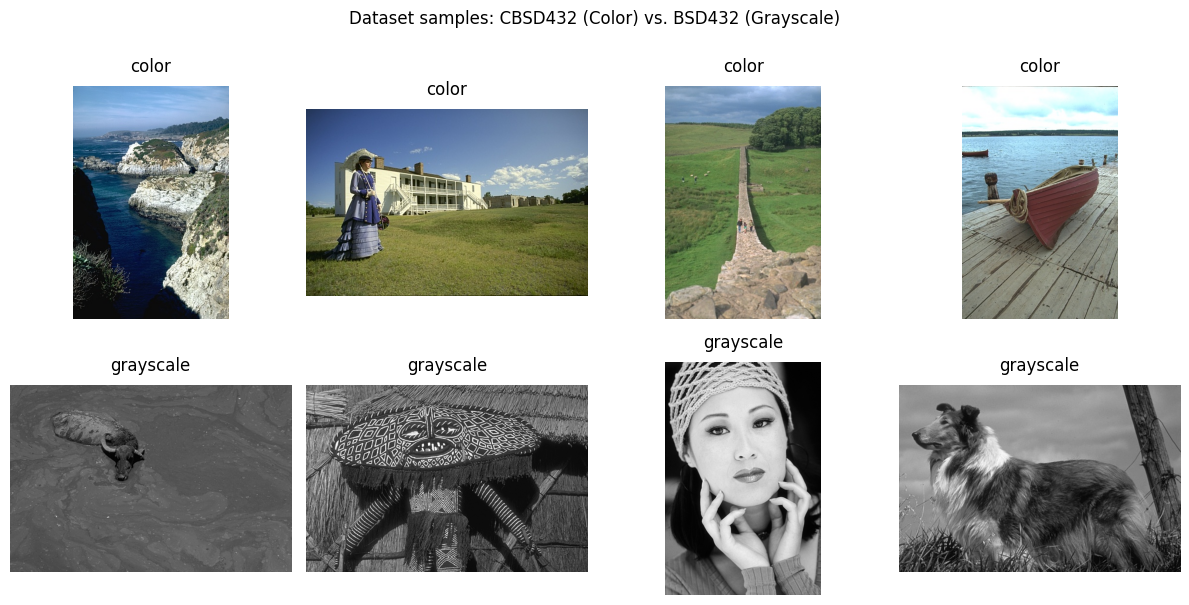

In [37]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = 4
images_list = preview_samples
n_img_rows = math.ceil(len(images_list) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 3 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_list):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_list), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("Dataset samples: CBSD432 (Color) vs. BSD432 (Grayscale)", y=1.0)
plt.tight_layout()
plt.show()


In [ ]:
# Load data

# Input data

# Solution

# Print results
